# Evkor Heart Disease Classification Demo

Educational portfolio project using the UCI Cleveland Heart Disease dataset. This is **not a medical device** and must not be used for diagnosis, screening, triage, or treatment decisions.

Run the code cell below. All data, training, and result files remain in the temporary Colab runtime unless you explicitly save them.


In [2]:
"""Educational heart-disease classification demo using the UCI Cleveland dataset.

This is a portfolio project, not a medical device and not for clinical use.
"""

from __future__ import annotations

import json
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


RANDOM_STATE = 42
DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
DATA_PATH = Path("/content/data/processed.cleveland.data")
RESULTS_DIR = Path("/content/results")

COLUMNS = [
    "age",
    "sex",
    "chest_pain_type",
    "resting_blood_pressure",
    "cholesterol",
    "fasting_blood_sugar",
    "resting_ecg",
    "max_heart_rate",
    "exercise_angina",
    "st_depression",
    "st_slope",
    "major_vessels",
    "thalassemia",
    "disease_severity",
]

NUMERIC_FEATURES = [
    "age",
    "resting_blood_pressure",
    "cholesterol",
    "max_heart_rate",
    "st_depression",
    "major_vessels",
]

CATEGORICAL_FEATURES = [
    "sex",
    "chest_pain_type",
    "fasting_blood_sugar",
    "resting_ecg",
    "exercise_angina",
    "st_slope",
    "thalassemia",
]


def load_data() -> tuple[pd.DataFrame, pd.Series]:
    DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    if not DATA_PATH.exists():
        print(f"Downloading the UCI Cleveland dataset to {DATA_PATH}")
        urlretrieve(DATA_URL, DATA_PATH)

    frame = pd.read_csv(DATA_PATH, names=COLUMNS, na_values="?")
    target = (frame.pop("disease_severity") > 0).astype(int)
    return frame, target


def make_preprocessor() -> ColumnTransformer:
    numeric = Pipeline(
        [
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]
    )
    categorical = Pipeline(
        [
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("one_hot", OneHotEncoder(handle_unknown="ignore")),
        ]
    )
    return ColumnTransformer(
        [
            ("numeric", numeric, NUMERIC_FEATURES),
            ("categorical", categorical, CATEGORICAL_FEATURES),
        ]
    )


def candidate_models() -> dict[str, Pipeline]:
    return {
        "logistic_regression": Pipeline(
            [
                ("preprocess", make_preprocessor()),
                (
                    "model",
                    LogisticRegression(
                        class_weight="balanced",
                        max_iter=2_000,
                        random_state=RANDOM_STATE,
                    ),
                ),
            ]
        ),
        "random_forest": Pipeline(
            [
                ("preprocess", make_preprocessor()),
                (
                    "model",
                    RandomForestClassifier(
                        n_estimators=400,
                        min_samples_leaf=4,
                        class_weight="balanced",
                        random_state=RANDOM_STATE,
                        n_jobs=-1,
                    ),
                ),
            ]
        ),
        "hist_gradient_boosting": Pipeline(
            [
                ("preprocess", make_preprocessor()),
                (
                    "model",
                    HistGradientBoostingClassifier(
                        max_iter=150,
                        learning_rate=0.05,
                        max_leaf_nodes=12,
                        l2_regularization=1.0,
                        random_state=RANDOM_STATE,
                    ),
                ),
            ]
        ),
    }


def subgroup_metrics(
    y_true: pd.Series,
    y_probability: np.ndarray,
    group: pd.Series,
) -> list[dict[str, float | int | str]]:
    rows: list[dict[str, float | int | str]] = []
    for value in sorted(group.unique()):
        mask = group == value
        labels = y_true.loc[mask]
        probabilities = y_probability[mask.to_numpy()]
        predictions = (probabilities >= 0.5).astype(int)
        rows.append(
            {
                "recorded_sex": "female" if value == 0 else "male",
                "n": int(mask.sum()),
                "prevalence": float(labels.mean()),
                "sensitivity": float(recall_score(labels, predictions, zero_division=0)),
                "specificity": float(recall_score(labels, predictions, pos_label=0, zero_division=0)),
                "roc_auc": float(roc_auc_score(labels, probabilities)),
            }
        )
    return rows


def main() -> None:
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    features, target = load_data()
    print(f"Rows: {len(features)} | Features: {features.shape[1]} | Positive rate: {target.mean():.1%}")
    print(f"Missing values: {int(features.isna().sum().sum())}")

    x_train, x_test, y_train, y_test = train_test_split(
        features,
        target,
        test_size=0.25,
        stratify=target,
        random_state=RANDOM_STATE,
    )

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    cv_rows = []
    models = candidate_models()
    for name, model in models.items():
        scores = cross_validate(
            model,
            x_train,
            y_train,
            cv=cv,
            scoring={"roc_auc": "roc_auc", "average_precision": "average_precision"},
            n_jobs=-1,
        )
        cv_rows.append(
            {
                "model": name,
                "cv_roc_auc_mean": float(scores["test_roc_auc"].mean()),
                "cv_roc_auc_std": float(scores["test_roc_auc"].std()),
                "cv_average_precision_mean": float(scores["test_average_precision"].mean()),
            }
        )

    cv_results = pd.DataFrame(cv_rows).sort_values("cv_roc_auc_mean", ascending=False)
    print("\nCross-validation on training data only:")
    print(cv_results.to_string(index=False, float_format=lambda value: f"{value:.3f}"))
    cv_results.to_csv(RESULTS_DIR / "cross_validation.csv", index=False)

    selected_name = str(cv_results.iloc[0]["model"])
    print(f"\nSelected before opening the test set: {selected_name}")
    calibrated_model = CalibratedClassifierCV(models[selected_name], method="sigmoid", cv=5)
    calibrated_model.fit(x_train, y_train)

    probability = calibrated_model.predict_proba(x_test)[:, 1]
    prediction = (probability >= 0.5).astype(int)
    matrix = confusion_matrix(y_test, prediction)
    tn, fp, fn, tp = matrix.ravel()

    metrics = {
        "selected_model": selected_name,
        "train_rows": int(len(x_train)),
        "test_rows": int(len(x_test)),
        "test_roc_auc": float(roc_auc_score(y_test, probability)),
        "test_average_precision": float(average_precision_score(y_test, probability)),
        "test_accuracy": float(accuracy_score(y_test, prediction)),
        "test_balanced_accuracy": float(balanced_accuracy_score(y_test, prediction)),
        "test_sensitivity": float(recall_score(y_test, prediction)),
        "test_specificity": float(tn / (tn + fp)),
        "test_precision": float(precision_score(y_test, prediction)),
        "test_brier_score": float(brier_score_loss(y_test, probability)),
        "confusion_matrix": matrix.tolist(),
    }
    (RESULTS_DIR / "metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")

    print("\nHeld-out test results:")
    for key, value in metrics.items():
        if key.startswith("test_"):
            print(f"{key.removeprefix('test_'):>20}: {value:.3f}")
    print("\nClassification report:")
    print(classification_report(y_test, prediction, target_names=["no disease", "disease"]))

    groups = subgroup_metrics(y_test, probability, x_test["sex"])
    pd.DataFrame(groups).to_csv(RESULTS_DIR / "subgroup_metrics.csv", index=False)
    print("Recorded-sex slices (exploratory only; the groups are small):")
    print(pd.DataFrame(groups).to_string(index=False, float_format=lambda value: f"{value:.3f}"))

    figure, axes = plt.subplots(1, 2, figsize=(10, 4))
    ConfusionMatrixDisplay(matrix, display_labels=["No disease", "Disease"]).plot(
        ax=axes[0], colorbar=False, cmap="Blues"
    )
    axes[0].set_title("Held-out confusion matrix")

    observed, predicted = calibration_curve(y_test, probability, n_bins=6, strategy="quantile")
    axes[1].plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
    axes[1].plot(predicted, observed, marker="o", color="#00796b", label="Model")
    axes[1].set(xlabel="Mean predicted probability", ylabel="Observed fraction", title="Calibration check")
    axes[1].legend()
    figure.tight_layout()
    figure.savefig(RESULTS_DIR / "evaluation.png", dpi=180, bbox_inches="tight")
    plt.close(figure)

    print(f"\nSaved results to {RESULTS_DIR}")
    print("\nIMPORTANT: This small, historical dataset cannot establish clinical validity.")
    print("The model must not be used to diagnose, triage, or guide treatment.")


if __name__ == "__main__":
    main()


Rows: 303 | Features: 13 | Positive rate: 45.9%
Missing values: 6

Cross-validation on training data only:
                 model  cv_roc_auc_mean  cv_roc_auc_std  cv_average_precision_mean
         random_forest            0.907           0.041                      0.901
   logistic_regression            0.900           0.042                      0.885
hist_gradient_boosting            0.884           0.046                      0.881

Selected before opening the test set: random_forest

Held-out test results:
                rows: 76.000
             roc_auc: 0.946
   average_precision: 0.944
            accuracy: 0.882
   balanced_accuracy: 0.884
         sensitivity: 0.914
         specificity: 0.854
           precision: 0.842
         brier_score: 0.100

Classification report:
              precision    recall  f1-score   support

  no disease       0.92      0.85      0.89        41
     disease       0.84      0.91      0.88        35

    accuracy                           0.88

## Visual evaluation

These plots evaluate discrimination, precision-recall trade-offs, calibration, errors, risk-score separation, and model sensitivity to each input. Feature importance is not evidence that a feature causes disease.


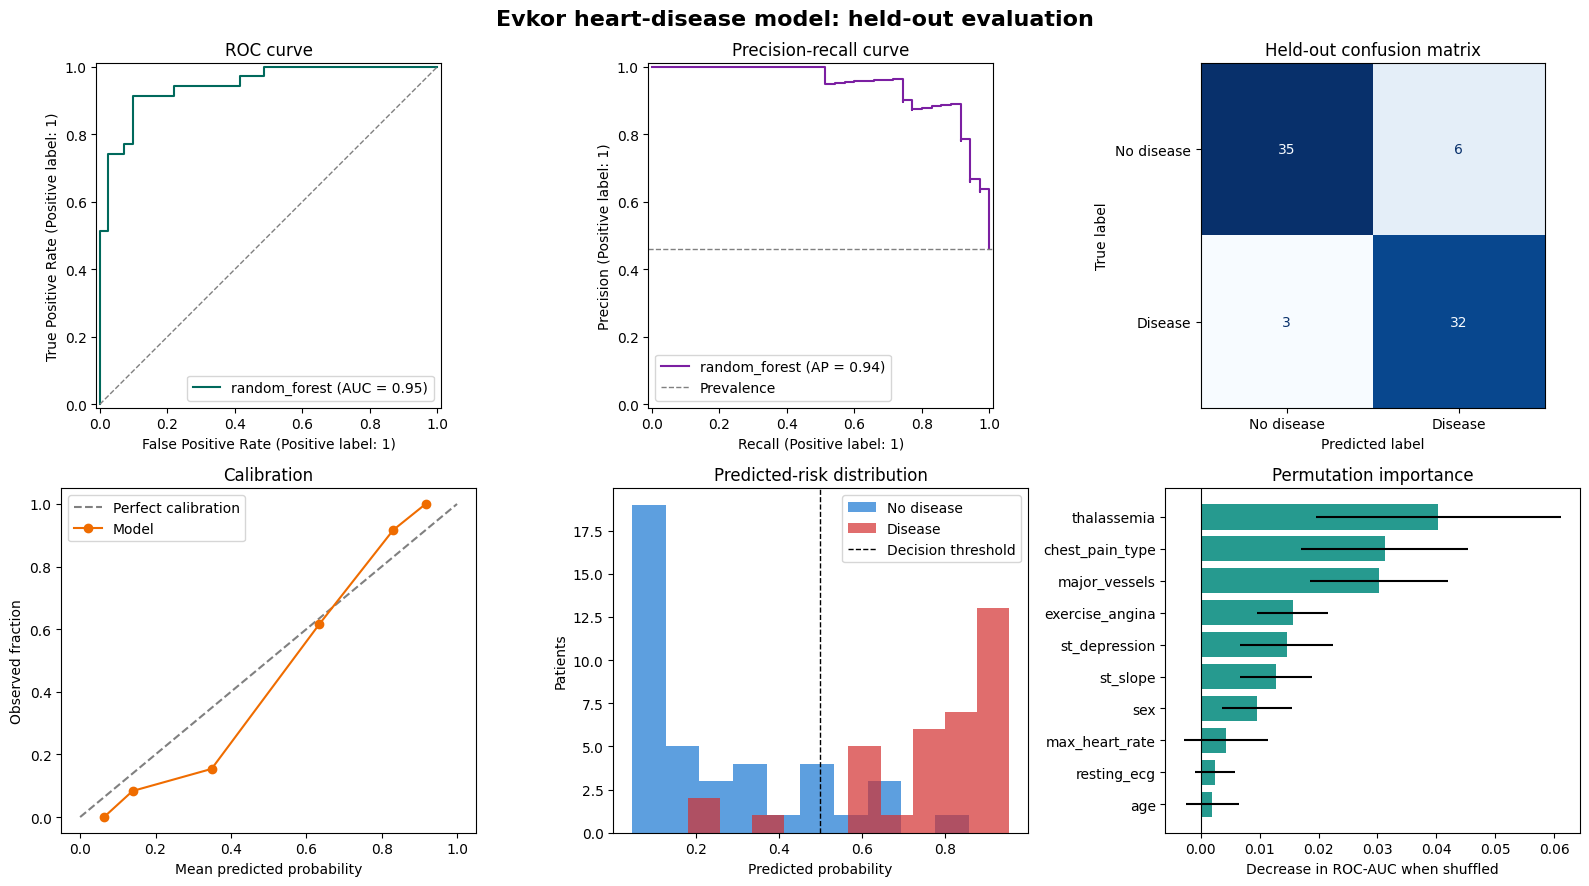

Important: feature importance describes this model and dataset; it does not establish medical causation.


In [4]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import PrecisionRecallDisplay, RocCurveDisplay

# Re-initialize variables needed for plotting from the previous cell's main function
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
features, target = load_data()

x_train, x_test, y_train, y_test = train_test_split(
    features,
    target,
    test_size=0.25,
    stratify=target,
    random_state=RANDOM_STATE,
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
models = candidate_models()

cv_rows = []
for name, model in models.items():
    scores = cross_validate(
        model,
        x_train,
        y_train,
        cv=cv,
        scoring={"roc_auc": "roc_auc", "average_precision": "average_precision"},
        n_jobs=-1,
    )
    cv_rows.append(
        {
            "model": name,
            "cv_roc_auc_mean": float(scores["test_roc_auc"].mean()),
            "cv_roc_auc_std": float(scores["test_roc_auc"].std()),
            "cv_average_precision_mean": float(scores["test_average_precision"].mean()),
        }
    )
cv_results = pd.DataFrame(cv_rows).sort_values("cv_roc_auc_mean", ascending=False)
selected_name = str(cv_results.iloc[0]["model"])

calibrated_model = CalibratedClassifierCV(models[selected_name], method="sigmoid", cv=5)
calibrated_model.fit(x_train, y_train)

probability = calibrated_model.predict_proba(x_test)[:, 1]
prediction = (probability >= 0.5).astype(int)
matrix = confusion_matrix(y_test, prediction)

observed, predicted = calibration_curve(y_test, probability, n_bins=6, strategy="quantile")

figure, axes = plt.subplots(2, 3, figsize=(16, 9))

RocCurveDisplay.from_predictions(
    y_test, probability, ax=axes[0, 0], color="#00695c", name=selected_name
)
axes[0, 0].plot([0, 1], [0, 1], "--", color="gray", linewidth=1)
axes[0, 0].set_title("ROC curve")

PrecisionRecallDisplay.from_predictions(
    y_test, probability, ax=axes[0, 1], color="#7b1fa2", name=selected_name
)
axes[0, 1].axhline(y_test.mean(), linestyle="--", color="gray", linewidth=1, label="Prevalence")
axes[0, 1].set_title("Precision-recall curve")
axes[0, 1].legend()

ConfusionMatrixDisplay(
    matrix, display_labels=["No disease", "Disease"]
).plot(ax=axes[0, 2], colorbar=False, cmap="Blues")
axes[0, 2].set_title("Held-out confusion matrix")

axes[1, 0].plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
axes[1, 0].plot(predicted, observed, marker="o", color="#ef6c00", label="Model")
axes[1, 0].set(
    xlabel="Mean predicted probability",
    ylabel="Observed fraction",
    title="Calibration",
)
axes[1, 0].legend()

axes[1, 1].hist(
    probability[y_test.to_numpy() == 0], bins=10, alpha=0.7, color="#1976d2", label="No disease"
)
axes[1, 1].hist(
    probability[y_test.to_numpy() == 1], bins=10, alpha=0.7, color="#d32f2f", label="Disease"
)
axes[1, 1].axvline(0.5, linestyle="--", color="black", linewidth=1, label="Decision threshold")
axes[1, 1].set(
    xlabel="Predicted probability",
    ylabel="Patients",
    title="Predicted-risk distribution",
)
axes[1, 1].legend()

importance = permutation_importance(
    calibrated_model,
    x_test,
    y_test,
    scoring="roc_auc",
    n_repeats=25,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
importance_frame = (
    pd.DataFrame(
        {
            "feature": x_test.columns,
            "importance": importance.importances_mean,
            "uncertainty": importance.importances_std,
        }
    )
    .sort_values("importance")
    .tail(10)
)
axes[1, 2].barh(
    importance_frame["feature"],
    importance_frame["importance"],
    xerr=importance_frame["uncertainty"],
    color="#00897b",
    alpha=0.85,
)
axes[1, 2].axvline(0, color="black", linewidth=0.8)
axes[1, 2].set(
    xlabel="Decrease in ROC-AUC when shuffled",
    title="Permutation importance",
)

figure.suptitle("Evkor heart-disease model: held-out evaluation", fontsize=16, fontweight="bold")
figure.tight_layout()
plt.show()

print("Important: feature importance describes this model and dataset; it does not establish medical causation.")


## How to read the output

- **ROC-AUC** measures ranking discrimination; 0.5 is random and 1.0 is perfect.
- **Sensitivity** is the share of positive cases detected.
- **Specificity** is the share of negative cases correctly rejected.
- **Brier score** measures probability error; lower is better.
- The held-out test set is small, so every result is uncertain and illustrative.
